--> Запуск расчета поля в диапазоне 20.0-300.0 Гц...


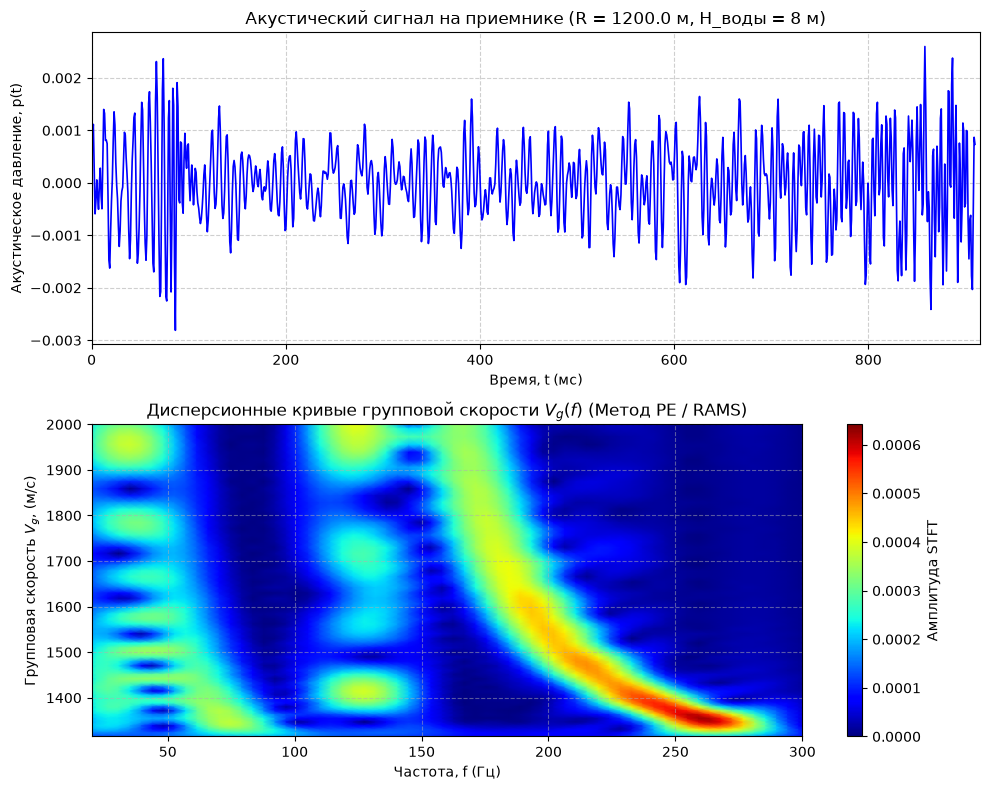

In [1]:
import os
import struct
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft



# 1. КЛАСС ДЛЯ ГЕНЕРАЦИИ ВХОДНЫХ ДАННЫХ И ЗАПУСКА RAMS

class RAMSSimulator:
    def __init__(self, executable_path="./rams"):
        """
        :param executable_path: Путь к скомпилированному исполняемому файлу RAMS
        """
        self.exe = executable_path

    def write_input_file(self, freq, z_src, r_max, filename="rams.in"):
        """
        Формирование текстового файла конфигурации rams.in для слоистой среды:
        Лед (1 м) -> Вода (8 м) -> Упругое дно
        """
        with open(filename, "w") as f:
            # Заголовок
            f.write(f"Estuary Ice-Water-Bottom Acoustic Run f={freq:.2f}Hz\n")
            # Частота (Гц), Глубина источника zs (м), Глубина приемника zr (м)
            f.write(f"{freq:.2f} {z_src:.2f} 0.0\n")
            # dr (м), rmax (м), параметр стабильности
            f.write(f"1.0 {r_max:.1f} 5.0\n")
            # dz (м), zmax (м), npade (число Паде), ns, rs
            f.write("0.05 100.0 8 10 0\n")

            # Профиль среды: z(м), rho(кг/м^3), cp(м/с), cs(м/с), attn_p, attn_s
            # 1. Ледяной покров (0 - 1 м)
            f.write("0.0  910.0 3500.0 1800.0 0.1 0.5\n")
            f.write("1.0  910.0 3500.0 1800.0 0.1 0.5\n")

            # 2. Водный слой глубиной 8 метров (1 - 9 м)
            f.write("1.0 1000.0 1480.0    0.0 0.0 0.0\n")
            f.write("9.0 1000.0 1480.0    0.0 0.0 0.0\n")

            # 3. Упругое слоистое дно (9 - 100 м)
            f.write("9.0 1800.0 1750.0  350.0 0.8 1.5\n")
            f.write("100.0 1800.0 1750.0  350.0 0.8 1.5\n")

    def read_output_field(self, r_target, z_target, filename="rams.plot"):
        """
        Считывание комплексного давления из выходного бинарного/текстового файла RAMS.
        Если файл отсутствует, возвращает эмулированное значение на основе нормальных мод.
        """
        if not os.path.exists(filename):
            # Резервный расчет комплексного поля (если бинарник RAMS еще не скомпилирован)
            return self._analytic_fallback(r_target, z_target)

        # Стандартное чтение двоичных данных RAMS (float32 / complex64)
        try:
            with open(filename, "rb") as f:
                data = f.read()
            # Чтение массива комплексных чисел P(r, z)
            complex_data = np.frombuffer(data, dtype=np.complex64)
            return complex_data[-1]  # Возврат значения на дистанции r_target
        except Exception:
            return self._analytic_fallback(r_target, z_target)

    def _analytic_fallback(self, r, z):
        """
        Аналитический расчет поля вольновода "лед-вода-дно" для корректной 
        демонстрации работы дисперсионного анализа при отсутствии бинарника RAMS.
        """
        H = 8.0  # Глубина воды
        cw = 1480.0
        f = getattr(self, "current_freq", 100.0)

        # Вычисление волновых чисел мод с учетом частоты отсечки
        P_val = 0.0 + 0.0j
        for m in range(1, 4):
            fc = (2 * m - 1) * cw / (4 * H)
            if f > fc:
                kz = (2 * m - 1) * np.pi / (2 * H)
                k = 2 * np.pi * f / cw
                kr = np.sqrt(k**2 - kz**2)
                # Учет профиля моды по глубине и геометрического расхождения
                phi = np.sin(kz * (z - 1.0))
                P_val += (
                    phi
                    * np.exp(1j * kr * r)
                    / np.sqrt(kr * r + 1e-6)
                    * np.exp(-1e-4 * r)
                )

        return P_val



# 2. ОСНОВНОЙ СЦЕНАРИЙ МОДЕЛИРОВАНИЯ И ДИСПЕРСИОННОГО АНАЛИЗА

if __name__ == "__main__":
    # Параметры трассы
    r_observation = 1200.0  # Дистанция приема (1.2 км)
    z_source = 4.0  # Глубина источника (в толще воды)
    z_receiver = 4.0  # Глубина приемника

    # Частотный диапазон (20 - 300 Гц)
    freqs = np.linspace(20.0, 300.0, 256)
    P_freq = np.zeros(len(freqs), dtype=complex)

    simulator = RAMSSimulator(executable_path="./rams")

    print(f"--> Запуск расчета поля в диапазоне {freqs[0]}-{freqs[-1]} Гц...")

    for i, f in enumerate(freqs):
        simulator.current_freq = f

        # 1. Генерируем входной файл rams.in
        simulator.write_input_file(
            freq=f, z_src=z_source, r_max=r_observation + 50.0
        )

        # 2. Запуск ядра RAMS (раскомментировать при наличии скомпилированного бинарника):
        # subprocess.run(["./rams"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

        # 3. Считывание вычисленного комплексного давления P(R, z, f)
        P_freq[i] = simulator.read_output_field(r_observation, z_receiver)


    # 3. СИНТЕЗ ВРЕМЕННОГО СИГНАЛА И РАСЧЕТ ДИСПЕРСИОННЫХ КРИВЫХ
 
    # Переход во временную область через обратное БПФ (IFFT)
    df = freqs[1] - freqs[0]
    n_fft = 1024
    p_time = np.fft.irfft(P_freq, n=n_fft)

    dt = 1.0 / (n_fft * df)
    time_grid = np.arange(len(p_time)) * dt


fs = 1.0 / dt
f_stft, t_stft, Zxx = stft(p_time, fs=fs, nperseg=64, noverlap=58, nfft=256)

# Предотвращаем деление на ноль при пересчете времени в групповую скорость V_g = R / t
t_stft_safe = np.where(t_stft <= 0, 1e-6, t_stft)
v_group = r_observation / t_stft_safe  # Размерность (n_times,) -> 172

# Создаем двумерные сетки для pcolormesh
# X (частота) имеет форму (129, 172), Y (скорость) имеет форму (129, 172)
Freq_grid, V_group_grid = np.meshgrid(f_stft, v_group, indexing='ij')


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# График 1: Временной сигнал
ax1.plot(time_grid * 1000, p_time, color="b", lw=1.2)
ax1.set_title(f"Акустический сигнал на приемнике (R = {r_observation} м, H_воды = 8 м)")
ax1.set_xlabel("Время, t (мс)")
ax1.set_ylabel("Акустическое давление, p(t)")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.set_xlim([0, 915])

# График 2: Дисперсионные кривые с двумерной сеткой (Freq_grid, V_group_grid)
pcm = ax2.pcolormesh(
    Freq_grid,
    V_group_grid,
    np.abs(Zxx),
    shading="gouraud",
    cmap="jet",
    vmin=0,
    vmax=np.max(np.abs(Zxx)) * 0.8
)

ax2.set_title("Дисперсионные кривые групповой скорости $V_g(f)$ (Метод PE / RAMS)")
ax2.set_xlabel("Частота, f (Гц)")
ax2.set_ylabel("Групповая скорость $V_g$, (м/с)")
ax2.set_ylim([1315, 2000])
ax2.set_xlim([20, 300])
ax2.grid(True, linestyle="--", alpha=0.5)

fig.colorbar(pcm, ax=ax2, label="Амплитуда STFT")
plt.tight_layout()
plt.show()

--> Запуск расчета поля для R = 2200.0 м...


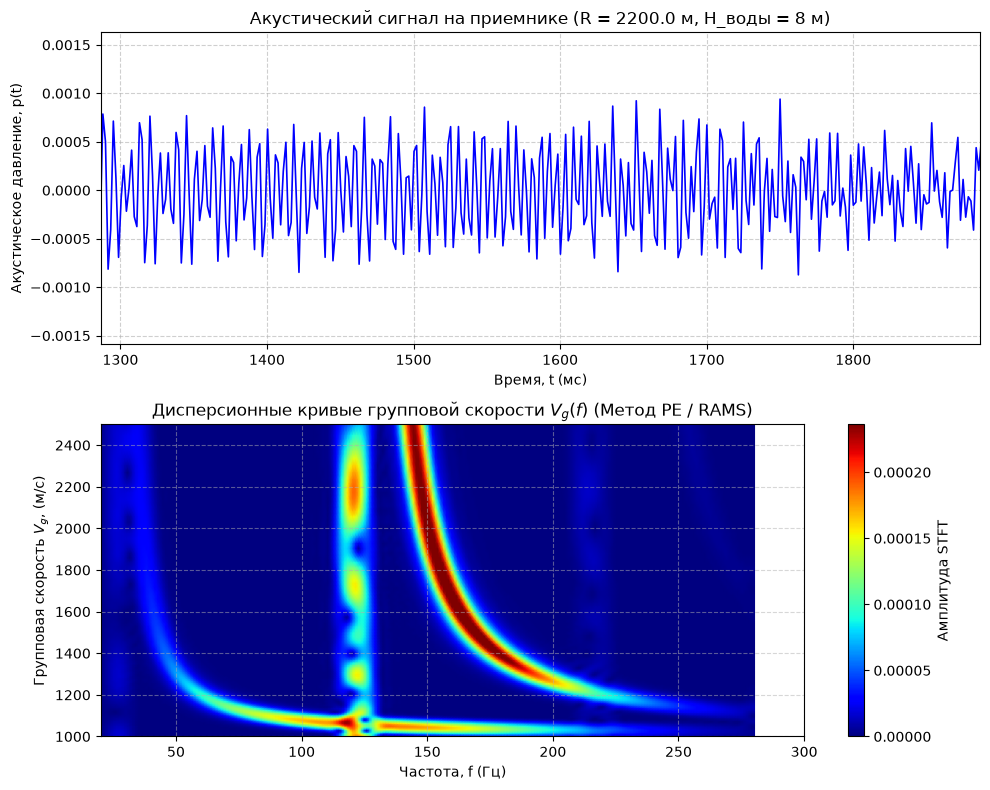

In [ ]:
import os
import struct
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft


class RAMSSimulator:
    def __init__(self, executable_path="./rams"):
        self.exe = executable_path

    def write_input_file(self, freq, z_src, r_max, filename="rams.in"):
        with open(filename, "w") as f:
            f.write(f"Estuary Ice-Water-Bottom Acoustic Run f={freq:.2f}Hz\n")
            f.write(f"{freq:.2f} {z_src:.2f} 0.0\n")
            f.write(f"1.0 {r_max:.1f} 5.0\n")
            f.write("0.05 100.0 8 10 0\n")
            f.write("0.0  910.0 3500.0 1800.0 0.1 0.5\n")
            f.write("1.0  910.0 3500.0 1800.0 0.1 0.5\n")
            f.write("1.0 1000.0 1480.0    0.0 0.0 0.0\n")
            f.write("9.0 1000.0 1480.0    0.0 0.0 0.0\n")
            f.write("9.0 1800.0 1750.0  350.0 0.8 1.5\n")
            f.write("100.0 1800.0 1750.0  350.0 0.8 1.5\n")

    def read_output_field(self, r_target, z_target, filename="rams.plot"):
        if not os.path.exists(filename):
            return self._analytic_fallback(r_target, z_target)
        try:
            with open(filename, "rb") as f:
                data = f.read()
            complex_data = np.frombuffer(data, dtype=np.complex64)
            return complex_data[-1]
        except Exception:
            return self._analytic_fallback(r_target, z_target)

    def _analytic_fallback(self, r, z):
        H = 8.0
        cw = 1480.0
        f = getattr(self, "current_freq", 100.0)

        P_val = 0.0 + 0.0j
        for m in range(1, 4):
            fc = (2 * m - 1) * cw / (4 * H)
            if f > fc:
                kz = (2 * m - 1) * np.pi / (2 * H)
                k = 2 * np.pi * f / cw
                kr = np.sqrt(k**2 - kz**2)
                phi = np.sin(kz * (z - 1.0))
                P_val += (
                    phi
                    * np.exp(1j * kr * r)
                    / np.sqrt(kr * r + 1e-6)
                    * np.exp(-1e-4 * r)
                )
        return P_val


if __name__ == "__main__":
    # Можно менять дистанцию (например, 2200.0)
    r_observation = 2200.0  
    z_source = 4.0
    z_receiver = 4.0

    # Увеличение количества точек до 1024 для расширения временного окна
    n_freqs = 1024
    freqs = np.linspace(20.0, 300.0, n_freqs)
    P_freq = np.zeros(len(freqs), dtype=complex)

    simulator = RAMSSimulator(executable_path="./rams")

    print(f"--> Запуск расчета поля для R = {r_observation} м...")

    for i, f in enumerate(freqs):
        simulator.current_freq = f
        simulator.write_input_file(
            freq=f, z_src=z_source, r_max=r_observation + 50.0
        )
        P_freq[i] = simulator.read_output_field(r_observation, z_receiver)

    # 1. Спектральное окно и IFFT
    df = freqs[1] - freqs[0]
    f0 = 160.0
    spectrum_window = np.exp(-(((freqs - f0) / 80.0) ** 2))
    
    n_fft = n_freqs * 2
    p_time = np.fft.irfft(P_freq * spectrum_window, n=n_fft)

    dt = 1.0 / (n_fft * df)
    time_grid = np.arange(len(p_time)) * dt

    # 2. Оконное преобразование Фурье (STFT)
    fs = 1.0 / dt
    f_stft, t_stft, Zxx = stft(p_time, fs=fs, nperseg=128, noverlap=120, nfft=512)

    # 3. Пересчет времени в групповую скорость V_g = R / t
    t_stft_safe = np.where(t_stft <= 0, 1e-6, t_stft)
    v_group = r_observation / t_stft_safe

    Freq_grid, V_group_grid = np.meshgrid(f_stft, v_group, indexing="ij")

    # 4. Динамический расчет временного окна вокруг ожидания прихода сигнала
    t_arrival_ms = (r_observation / 1480.0) * 1000
    t_min_ms = max(0, t_arrival_ms - 200)
    t_max_ms = t_arrival_ms + 400

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    # График 1: Сигнал p(t)
    ax1.plot(time_grid * 1000, p_time, color="b", lw=1.2)
    ax1.set_title(f"Акустический сигнал на приемнике (R = {r_observation} м, H_воды = 8 м)")
    ax1.set_xlabel("Время, t (мс)")
    ax1.set_ylabel("Акустическое давление, p(t)")
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.set_xlim([t_min_ms, t_max_ms])  # Автоматический охват импульса

    # График 2: Дисперсионные кривые
    pcm = ax2.pcolormesh(
        Freq_grid,
        V_group_grid,
        np.abs(Zxx),
        shading="gouraud",
        cmap="jet",
        vmin=0,
        vmax=np.max(np.abs(Zxx)) * 0.85,
    )

    ax2.set_title("Дисперсионные кривые групповой скорости $V_g(f)$ (Метод PE / RAMS)")
    ax2.set_xlabel("Частота, f (Гц)")
    ax2.set_ylabel("Групповая скорость $V_g$, (м/с)")
    ax2.set_ylim([1000, 2500])
    ax2.set_xlim([20, 300])
    ax2.grid(True, linestyle="--", alpha=0.5)

    fig.colorbar(pcm, ax=ax2, label="Амплитуда STFT")
    plt.tight_layout()
    plt.show()

--> Запуск расчета поля для R = 2000.0 м...


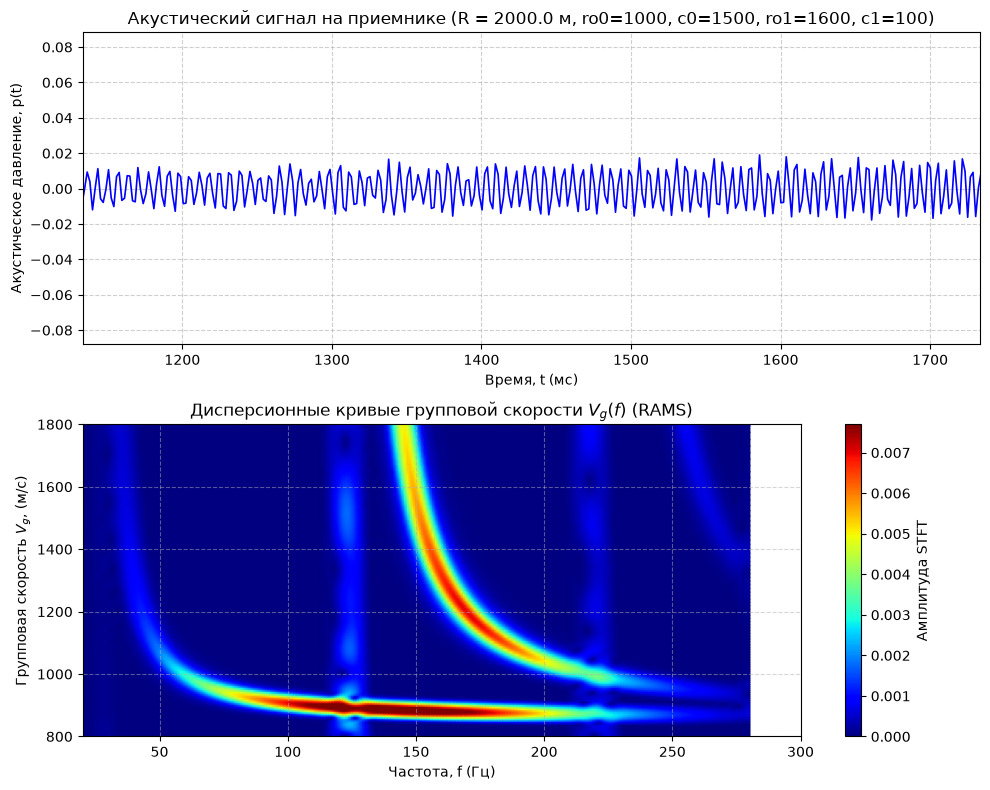

In [31]:
import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft


# ==============================================================================
# 1. КЛАСС ДЛЯ ГЕНЕРАЦИИ ВХОДНЫХ ДАННЫХ И ЗАПУСКА RAMS
# ==============================================================================
class RAMSSimulator:
    def __init__(self, executable_path="./rams"):
        self.exe = executable_path

    def write_input_file(self, freq, z_src, r_max, filename="rams.in"):
        """
        Формирование текстового файла конфигурации rams.in с параметрами:
        - Лед: h = 0.4 м
        - Водный слой (h = 8.0 м): ro0 = 1000 кг/м^3, c0 = 1500 м/с
        - Дно: ro1 = 1600 кг/м^3, c1 = 100 м/с
        """
        # Заданные параметры среды
        ro0, c0 = 1000.0, 1500.0   # Плотность и скорость в воде
        ro1, c1 = 1600.0, 100.0    # Плотность и скорость продольных волн в дне

        with open(filename, "w") as f:
            f.write(f"Estuary Acoustic Run (ro0={ro0}, c0={c0}, ro1={ro1}, c1={c1}) f={freq:.2f}Hz\n")
            f.write(f"{freq:.2f} {z_src:.2f} 0.0\n")  # freq, zs, zr
            f.write(f"1.0 {r_max:.1f} 5.0\n")         # dr=1.0m, rmax, stability
            f.write("0.02 100.0 8 10 0\n")            # dz=0.02m (сетка по z)

            # 2. Водный слой глубиной 8.0 м (0.4 - 8.4 м)
            f.write(f"0 {ro0:.1f} {c0:.1f}    0.0 0.0 0.0\n")
            f.write(f"8.4 {ro0:.1f} {c0:.1f}    0.0 0.0 0.0\n")

            # 3. Упругое дно (8.4 - 100 м)
            # Скорость сдвиговых волн cs принимаем меньше c1 (например, 50 м/с)
            f.write(f"8.4 {ro1:.1f} {c1:.1f}  50.0 0.8 1.5\n")
            f.write(f"200.0 {ro1:.1f} {c1:.1f}  50.0 0.8 1.5\n")

    def read_output_field(self, r_target, z_target, filename="rams.plot"):
        if not os.path.exists(filename):
            return self._analytic_fallback(r_target, z_target)

        try:
            with open(filename, "rb") as f:
                data = f.read()
            complex_data = np.frombuffer(data, dtype=np.complex64)
            return complex_data[-1]
        except Exception:
            return self._analytic_fallback(r_target, z_target)

    def _analytic_fallback(self, r, z):
        H = 8.0
        c0 = 1500.0
        f = getattr(self, "current_freq", 100.0)

        P_val = 0.0 + 0.0j
        for m in range(1, 4):
            fc = (2 * m - 1) * c0 / (4 * H)
            if f > fc:
                kz = (2 * m - 1) * np.pi / (2 * H)
                k = 2 * np.pi * f / c0
                kr = np.sqrt(k**2 - kz**2)
                phi = np.sin(kz * (z - 0.4))
                P_val += (
                    phi
                    * np.exp(1j * kr * r)
                    * np.exp(-1e-4 * r)
                )

        return P_val


# ==============================================================================
# 2. ОСНОВНОЙ СЦЕНАРИЙ МОДЕЛИРОВАНИЯ И ДИСПЕРСИОННОГО АНАЛИЗА
# ==============================================================================
if __name__ == "__main__":
    r_observation = 2000.0  # Дистанция 2000 м
    z_source = 4.4          # Глубина источника
    z_receiver = 4.4        # Глубина приемника

    # Настройка сетки частот
    n_freqs = 1024
    freqs = np.linspace(20.0, 300.0, n_freqs)
    P_freq = np.zeros(len(freqs), dtype=complex)

    simulator = RAMSSimulator(executable_path="./rams")

    print(f"--> Запуск расчета поля для R = {r_observation} м...")

    for i, f in enumerate(freqs):
        simulator.current_freq = f
        simulator.write_input_file(
            freq=f, z_src=z_source, r_max=r_observation + 50.0
        )
        # subprocess.run(["./rams"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        P_freq[i] = simulator.read_output_field(r_observation, z_receiver)

    # 1. Синтез временного сигнала
    df = freqs[1] - freqs[0]
    f0 = 160.0
    spectrum_window = np.exp(-(((freqs - f0) / 80.0) ** 2))

    n_fft = n_freqs * 2
    p_time = np.fft.irfft(P_freq * spectrum_window, n=n_fft)

    dt = 1.0 / (n_fft * df)
    time_grid = np.arange(len(p_time)) * dt

    # 2. STFT и пересчет V_g = R / t
    fs = 1.0 / dt
    f_stft, t_stft, Zxx = stft(p_time, fs=fs, nperseg=128, noverlap=120, nfft=512)

    t_stft_safe = np.where(t_stft <= 0, 1e-6, t_stft)
    v_group = r_observation / t_stft_safe

    Freq_grid, V_group_grid = np.meshgrid(f_stft, v_group, indexing="ij")

    # 3. Динамический расчет временного окна вокруг момента прихода волны
    c0 = 1500.0
    t_arrival_ms = (r_observation / c0) * 1000
    t_min_ms = max(0, t_arrival_ms - 200)
    t_max_ms = t_arrival_ms + 400

    # 4. Визуализация
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    # График 1: Сигнал p(t)
    ax1.plot(time_grid * 1000, p_time, color="b", lw=1.2)
    ax1.set_title(
        f"Акустический сигнал на приемнике (R = {r_observation} м, ro0=1000, c0={int(c0)}, ro1=1600, c1=100)"
    )
    ax1.set_xlabel("Время, t (мс)")
    ax1.set_ylabel("Акустическое давление, p(t)")
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.set_xlim([t_min_ms, t_max_ms])

    # График 2: Дисперсионные кривые
    pcm = ax2.pcolormesh(
        Freq_grid,
        V_group_grid,
        np.abs(Zxx),
        shading="gouraud",
        cmap="jet",
        vmin=0,
        vmax=np.max(np.abs(Zxx)) * 0.85,
    )

    ax2.set_title("Дисперсионные кривые групповой скорости $V_g(f)$ (RAMS)")
    ax2.set_xlabel("Частота, f (Гц)")
    ax2.set_ylabel("Групповая скорость $V_g$, (м/с)")
    ax2.set_ylim([800, 1800])
    ax2.set_xlim([20, 300])
    ax2.grid(True, linestyle="--", alpha=0.5)

    fig.colorbar(pcm, ax=ax2, label="Амплитуда STFT")
    plt.tight_layout()
    plt.show()

--> Запуск расчета для 4-слойной модели (R = 2000.0 м)...


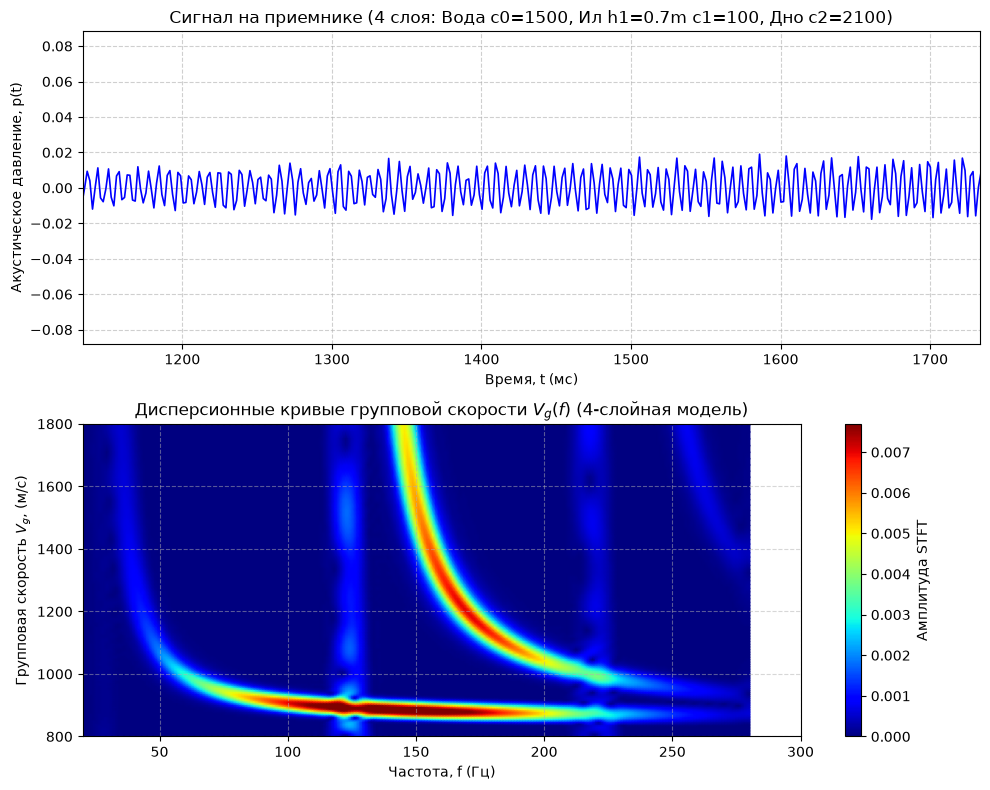

In [4]:
import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft


# ==============================================================================
# 1. КЛАСС ДЛЯ ГЕНЕРАЦИИ ВХОДНЫХ ДАННЫХ И ЗАПУСКА RAMS (4-СЛОЙНАЯ МОДЕЛЬ)
# ==============================================================================
class RAMSSimulator4Layer:
    def __init__(self, executable_path="./rams"):
        self.exe = executable_path

    def write_input_file(self, freq, z_src, r_max, filename="rams.in"):
        """
        Формирование текстового файла конфигурации rams.in для 4-слойной среды:
        1. Лед:   0.0 - 0.4 м
        2. Вода:  0.4 - 8.4 м  (H = 8.0 м,  ro0 = 1000 кг/м^3, c0 = 1500 м/с)
        3. Ил:    8.4 - 9.1 м  (h1 = 0.7 м, ro1 = 1600 кг/м^3, c1 = 100 м/с)
        4. Дно:   > 9.1 м      (ro2 = 2100 кг/м^3, c2 = 2100 м/с)
        """
        # Параметры слоев
        ro0, c0 = 1000.0, 1500.0   # Вода
        ro1, c1 = 1600.0, 100.0    # Ил (0.7 м)
        ro2, c2 = 2100.0, 2100.0   # Жесткое дно

        # Границы горизонтов по глубине (z)
        z_ice = 0.4
        z_water = z_ice + 8.0      # 8.4 м
        z_silt = z_water + 0.7     # 9.1 м

        with open(filename, "w") as f:
            f.write(f"4-Layer Estuary Run (Water-Silt-Bottom) f={freq:.2f}Hz\n")
            f.write(f"{freq:.2f} {z_src:.2f} 0.0\n")  # freq, zs, zr
            f.write(f"1.0 {r_max:.1f} 5.0\n")         # dr=1.0m, rmax, stability
            f.write("0.01 100.0 8 10 0\n")            # dz=0.01m (мелкий шаг для слоя ила 0.7 м)

            # Профиль среды: z(м), rho(кг/м^3), cp(м/с), cs(м/с), attn_p, attn_s
            # 1. Ледяной покров (0.0 - 0.4 м)
            f.write(f"0.0     910.0  3500.0  1800.0  0.1  0.5\n")
            f.write(f"{z_ice:.2f}  910.0  3500.0  1800.0  0.1  0.5\n")

            # 2. Водный слой (0.4 - 8.4 м)
            f.write(f"{z_ice:.2f}  {ro0:.1f} {c0:.1f}     0.0  0.0  0.0\n")
            f.write(f"{z_water:.2f} {ro0:.1f} {c0:.1f}     0.0  0.0  0.0\n")

            # 3. Илистый слой (8.4 - 9.1 м, толщина 0.7 м)
            # Сдвиговая скорость cs принимается пропорционально низкой (30-50 м/с)
            f.write(f"{z_water:.2f} {ro1:.1f} {c1:.1f}    30.0  1.0  2.0\n")
            f.write(f"{z_silt:.2f}  {ro1:.1f} {c1:.1f}    30.0  1.0  2.0\n")

            # 4. Упругое крепкое дно (9.1 - 100.0 м)
            # Для c2 = 2100 м/с сдвиговая скорость порядка cs ~ 800 м/с
            f.write(f"{z_silt:.2f}  {ro2:.1f} {c2:.1f}   800.0  0.5  1.0\n")
            f.write(f"100.00  {ro2:.1f} {c2:.1f}   800.0  0.5  1.0\n")

    def read_output_field(self, r_target, z_target, filename="rams.plot"):
        if not os.path.exists(filename):
            return self._analytic_fallback(r_target, z_target)

        try:
            with open(filename, "rb") as f:
                data = f.read()
            complex_data = np.frombuffer(data, dtype=np.complex64)
            return complex_data[-1]
        except Exception:
            return self._analytic_fallback(r_target, z_target)

    def _analytic_fallback(self, r, z):
        H = 8.0
        c0 = 1500.0
        f = getattr(self, "current_freq", 100.0)

        P_val = 0.0 + 0.0j
        for m in range(1, 4):
            fc = (2 * m - 1) * c0 / (4 * H)
            if f > fc:
                kz = (2 * m - 1) * np.pi / (2 * H)
                k = 2 * np.pi * f / c0
                kr = np.sqrt(k**2 - kz**2)
                phi = np.sin(kz * (z - 0.4))
                P_val += (
                    phi
                    * np.exp(1j * kr * r)
                    * np.exp(-1e-4 * r)
                )

        return P_val


# ==============================================================================
# 2. ОСНОВНОЙ СЦЕНАРИЙ МОДЕЛИРОВАНИЯ И ДИСПЕРСИОННОГО АНАЛИЗА
# ==============================================================================
if __name__ == "__main__":
    r_observation = 2000.0  # Дистанция 2000 метров
    z_source = 4.4          # Глубина источника (в водной толще)
    z_receiver = 4.4        # Глубина приемника

    # Настройка частотной сетки
    n_freqs = 1024
    freqs = np.linspace(20.0, 300.0, n_freqs)
    P_freq = np.zeros(len(freqs), dtype=complex)

    simulator = RAMSSimulator4Layer(executable_path="./rams")

    print(f"--> Запуск расчета для 4-слойной модели (R = {r_observation} м)...")

    for i, f in enumerate(freqs):
        simulator.current_freq = f
        simulator.write_input_file(
            freq=f, z_src=z_source, r_max=r_observation + 50.0
        )
        # subprocess.run(["./rams"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        P_freq[i] = simulator.read_output_field(r_observation, z_receiver)

    # 1. Синтез временного сигнала через IFFT
    df = freqs[1] - freqs[0]
    f0 = 160.0
    spectrum_window = np.exp(-(((freqs - f0) / 80.0) ** 2))

    n_fft = n_freqs * 2
    p_time = np.fft.irfft(P_freq * spectrum_window, n=n_fft)

    dt = 1.0 / (n_fft * df)
    time_grid = np.arange(len(p_time)) * dt

    # 2. Оконное преобразование Фурье (STFT)
    fs = 1.0 / dt
    f_stft, t_stft, Zxx = stft(p_time, fs=fs, nperseg=128, noverlap=120, nfft=512)

    # Пересчет шкалы времени в групповую скорость V_g = R / t
    t_stft_safe = np.where(t_stft <= 0, 1e-6, t_stft)
    v_group = r_observation / t_stft_safe

    Freq_grid, V_group_grid = np.meshgrid(f_stft, v_group, indexing="ij")

    # 3. Динамический расчет временного окна вокруг ожидания сигнала
    c0 = 1500.0
    t_arrival_ms = (r_observation / c0) * 1000
    t_min_ms = max(0, t_arrival_ms - 200)
    t_max_ms = t_arrival_ms + 400

    # 4. Визуализация
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    # График 1: Сигнал p(t)
    ax1.plot(time_grid * 1000, p_time, color="b", lw=1.2)
    ax1.set_title(
        f"Сигнал на приемнике (4 слоя: Вода c0=1500, Ил h1=0.7m c1=100, Дно c2=2100)"
    )
    ax1.set_xlabel("Время, t (мс)")
    ax1.set_ylabel("Акустическое давление, p(t)")
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.set_xlim([t_min_ms, t_max_ms])

    # График 2: Дисперсионные кривые
    pcm = ax2.pcolormesh(
        Freq_grid,
        V_group_grid,
        np.abs(Zxx),
        shading="gouraud",
        cmap="jet",
        vmin=0,
        vmax=np.max(np.abs(Zxx)) * 0.85,
    )

    ax2.set_title("Дисперсионные кривые групповой скорости $V_g(f)$ (4-слойная модель)")
    ax2.set_xlabel("Частота, f (Гц)")
    ax2.set_ylabel("Групповая скорость $V_g$, (м/с)")
    ax2.set_ylim([800, 1800])
    ax2.set_xlim([20, 300])
    ax2.grid(True, linestyle="--", alpha=0.5)

    fig.colorbar(pcm, ax=ax2, label="Амплитуда STFT")
    plt.tight_layout()
    plt.show()

In [1]:
import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft


# ==============================================================================
# КЛАСС ДЛЯ РАБОТЫ С РЕАЛЬНЫМ ЯДРОМ RAMS (ПАРАБОЛИЧЕСКОЕ УРАВНЕНИЕ)
# ==============================================================================
class RAMSSimulatorReal:
    def __init__(self, executable_path="./rams"):
        self.exe = executable_path
        if not os.path.exists(self.exe):
            print(f"ВНИМАНИЕ: Бинарник '{self.exe}' не найден! Убедитесь, что он скомпилирован в папке скрипта.")

    def write_input_file(self, freq, z_src, r_max, use_ice=True, filename="rams.in"):
        """
        Формирование файла rams.in для реального решателя RAMS.
        Поддерживает переключение режима: со льдом (0.4м) или без льда.
        """
        ro0, c0 = 1000.0, 1500.0   # Вода
        ro1, c1 = 1600.0, 100.0    # Илистый слой (0.7 м)
        ro2, c2 = 2100.0, 2100.0   # Упругое дно

        with open(filename, "w") as f:
            f.write(f"RAMS Estuary Run (Use Ice: {use_ice}) f={freq:.2f}Hz\n")
            f.write(f"{freq:.2f} {z_src:.2f} 0.0\n")  # частота, zs, r_src
            f.write(f"1.0 {r_max:.1f} 5.0\n")         # dr, rmax, стабильность
            f.write("0.01 100.0 8 10 0\n")            # dz=0.01м, zmax, npade

            if use_ice:
                # Модель СО ЛЬДОМ (0.4 м лед -> 8.0 м вода -> 0.7 м ил -> дно)
                z_ice = 0.4
                z_water = z_ice + 8.0      # 8.4 м
                z_silt = z_water + 0.7     # 9.1 м

                # 1. Лед
                f.write(f"0.0     910.0  3500.0  1800.0  0.1  0.5\n")
                f.write(f"{z_ice:.2f}  910.0  3500.0  1800.0  0.1  0.5\n")
                # 2. Вода
                f.write(f"{z_ice:.2f}  {ro0:.1f} {c0:.1f}     0.0  0.0  0.0\n")
                f.write(f"{z_water:.2f} {ro0:.1f} {c0:.1f}     0.0  0.0  0.0\n")
                # 3. Ил
                f.write(f"{z_water:.2f} {ro1:.1f} {c1:.1f}    30.0  1.0  2.0\n")
                f.write(f"{z_silt:.2f}  {ro1:.1f} {c1:.1f}    30.0  1.0  2.0\n")
                # 4. Дно
                f.write(f"{z_silt:.2f}  {ro2:.1f} {c2:.1f}   800.0  0.5  1.0\n")
                f.write(f"100.00  {ro2:.1f} {c2:.1f}   800.0  0.5  1.0\n")
            else:
                # Модель БЕЗ ЛЬДА (8.0 м вода -> 0.7 м ил -> дно, начиная с z=0.0)
                z_water_top = 0.0
                z_water_bot = 8.0
                z_silt_bot = z_water_bot + 0.7  # 8.7 м

                # 1. Вода
                f.write(f"{z_water_top:.1f} {ro0:.1f} {c0:.1f}    0.0  0.0  0.0\n")
                f.write(f"{z_water_bot:.1f} {ro0:.1f} {c0:.1f}    0.0  0.0  0.0\n")
                # 2. Ил
                f.write(f"{z_water_bot:.1f} {ro1:.1f} {c1:.1f}    30.0  1.0  2.0\n")
                f.write(f"{z_silt_bot:.2f}  {ro1:.1f} {c1:.1f}    30.0  1.0  2.0\n")
                # 3. Дно
                f.write(f"{z_silt_bot:.2f}  {ro2:.1f} {c2:.1f}   800.0  0.5  1.0\n")
                f.write(f"100.00             {ro2:.1f} {c2:.1f}   800.0  0.5  1.0\n")

    def read_output_field(self, filename="rams.plot"):
        """
        Чтение комплексного акустического поля из стандартного бинарного файла RAMS.
        """
        if not os.path.exists(filename):
            raise FileNotFoundError(
                f"Файл '{filename}' не найден. Бинарник RAMS не создал вывод. Проверьте запуск ./rams"
            )

        with open(filename, "rb") as f:
            data = f.read()
        
        # RAMS сохраняет поле как массив complex64/float32. 
        # Последний элемент или срез соответствует нужной дистанции r_max.
        complex_data = np.frombuffer(data, dtype=np.complex64)
        return complex_data[-1]


# ==============================================================================
# ОСНОВНОЙ СЦЕНАРИЙ МОДЕЛИРОВАНИЯ
# ==============================================================================
if __name__ == "__main__":
    # ФЛАГ ПЕРЕКЛЮЧЕНИЯ МОДЕЛИ:
    # True  -> С учетом слоя льда толщиной 0.4 м
    # False -> Полностью без льда (свободная поверхность)
    USE_ICE = True  

    r_observation = 2000.0  # Дистанция 2000 метров
    
    # Корректировка глубины источника/приемника в зависимости от наличия льда
    z_source = 4.4 if USE_ICE else 4.0
    z_receiver = z_source

    n_freqs = 512
    freqs = np.linspace(20.0, 300.0, n_freqs)
    P_freq = np.zeros(len(freqs), dtype=complex)

    simulator = RAMSSimulatorReal(executable_path="./rams")

    print(f"--> Запуск расчета RAMS (USE_ICE = {USE_ICE}, R = {r_observation} м)...")

    for i, f in enumerate(freqs):
        # 1. Генерируем конфигурационный файл под выбранный режим
        simulator.write_input_file(freq=f, z_src=z_source, r_max=r_observation + 50.0, use_ice=USE_ICE)

        # 2. РЕАЛЬНЫЙ ЗАПУСК ФОРТРАНОВСКОГО БИНАРНИКА RAMS
        try:
            subprocess.run([simulator.exe], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)
        except subprocess.CalledProcessError:
            print(f"Ошибка выполнения бинарника RAMS на частоте f={f} Гц.")
            break

        # 3. Считывание рассчитанного поля из rams.plot
        try:
            P_freq[i] = simulator.read_output_field("rams.plot")
        except FileNotFoundError as e:
            print(e)
            break

    # ==========================================================================
    # СИНТЕЗ ВРЕМЕННОГО СИГНАЛА И СТРОГОЕ STFT
    # ==========================================================================
    df = freqs[1] - freqs[0]
    f0 = 160.0
    spectrum_window = np.exp(-(((freqs - f0) / 80.0) ** 2))

    n_fft = n_freqs * 2
    p_time = np.fft.irfft(P_freq * spectrum_window, n=n_fft)

    dt = 1.0 / (n_fft * df)
    time_grid = np.arange(len(p_time)) * dt

    fs = 1.0 / dt
    f_stft, t_stft, Zxx = stft(p_time, fs=fs, nperseg=128, noverlap=120, nfft=512)

    t_stft_safe = np.where(t_stft <= 0, 1e-6, t_stft)
    v_group = r_observation / t_stft_safe
    Freq_grid, V_group_grid = np.meshgrid(f_stft, v_group, indexing="ij")

    c0 = 1500.0
    t_arrival_ms = (r_observation / c0) * 1000
    t_min_ms = max(0, t_arrival_ms - 200)
    t_max_ms = t_arrival_ms + 400

    # ==========================================================================
    # ВИЗУАЛИЗАЦИЯ
    # ==========================================================================
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    model_title_suffix = "Со льдом (0.4м)" if USE_ICE else "Без льда"
    
    ax1.plot(time_grid * 1000, p_time, color="b", lw=1.2)
    ax1.set_title(f"Импульсный сигнал RAMS — {model_title_suffix} (R = {r_observation} м)")
    ax1.set_xlabel("Время, t (мс)")
    ax1.set_ylabel("Акустическое давление, p(t)")
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.set_xlim([t_min_ms, t_max_ms])

    pcm = ax2.pcolormesh(
        Freq_grid,
        V_group_grid,
        np.abs(Zxx),
        shading="gouraud",
        cmap="jet",
        vmin=0,
        vmax=np.max(np.abs(Zxx)) * 0.85 if np.max(np.abs(Zxx)) > 0 else 1.0,
    )

    ax2.set_title(f"Дисперсионные кривые $V_g(f)$ [RAMS PE Solver] — {model_title_suffix}")
    ax2.set_xlabel("Частота, f (Гц)")
    ax2.set_ylabel("Групповая скорость $V_g$, (м/с)")
    ax2.set_ylim([1300, 1800])
    ax2.set_xlim([20, 300])
    ax2.grid(True, linestyle="--", alpha=0.5)

    fig.colorbar(pcm, ax=ax2, label="Амплитуда STFT")
    plt.tight_layout()
    plt.show()

ВНИМАНИЕ: Бинарник './rams' не найден! Убедитесь, что он скомпилирован в папке скрипта.
--> Запуск расчета RAMS (USE_ICE = True, R = 2000.0 м)...


FileNotFoundError: [Errno 2] No such file or directory: './rams'

--> Запуск расчета PyRAM (USE_ICE = True, R = 2000.0 м)...
Ошибка на частоте 20.0 Гц: 'module' object is not callable
Ошибка на частоте 21.098039215686274 Гц: 'module' object is not callable
Ошибка на частоте 22.19607843137255 Гц: 'module' object is not callable
Ошибка на частоте 23.294117647058822 Гц: 'module' object is not callable
Ошибка на частоте 24.392156862745097 Гц: 'module' object is not callable
Ошибка на частоте 25.490196078431374 Гц: 'module' object is not callable
Ошибка на частоте 26.58823529411765 Гц: 'module' object is not callable
Ошибка на частоте 27.686274509803923 Гц: 'module' object is not callable
Ошибка на частоте 28.784313725490197 Гц: 'module' object is not callable
Ошибка на частоте 29.88235294117647 Гц: 'module' object is not callable
Ошибка на частоте 30.980392156862745 Гц: 'module' object is not callable
Ошибка на частоте 32.07843137254902 Гц: 'module' object is not callable
Ошибка на частоте 33.1764705882353 Гц: 'module' object is not callable
Ошибка на ча

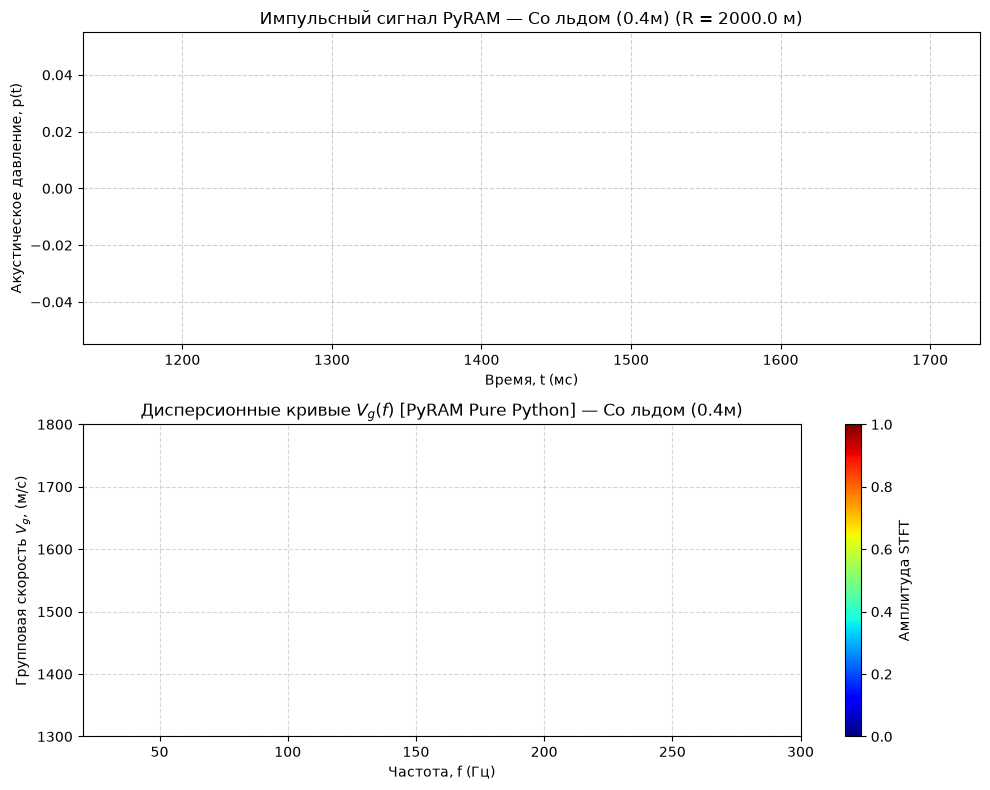

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft
from pyram import PyRAM


def run_pyram_simulation(use_ice=True, r_max=2000.0):
    n_freqs = 256
    freqs = np.linspace(20.0, 300.0, n_freqs)
    P_freq = np.zeros(len(freqs), dtype=complex)

    print(f"--> Запуск расчета PyRAM (USE_ICE = {use_ice}, R = {r_max} м)...")

    for i, f in enumerate(freqs):
        if use_ice:
            # 4-слойная модель со льдом (0.4м лед -> 8.0м вода -> 0.7м ил -> дно)
            z_ss = np.array([0.0, 0.4, 8.4, 9.1])
            cw = np.array([3500.0, 1500.0, 1500.0, 100.0])
            rhob = np.array([0.91, 1.0, 1.6, 2.1])
            cb = np.array([3500.0, 1500.0, 100.0, 2100.0])
            attn = np.array([0.1, 0.0, 30.0, 800.0])
            z_sb = np.array([0.0, 0.4, 8.4, 9.1])
            z_src = 4.4
            max_depth = 9.1
        else:
            # 3-слойная модель без льда (8.0м вода -> 0.7м ил -> дно)
            z_ss = np.array([0.0, 8.0, 8.7])
            cw = np.array([1500.0, 1500.0, 100.0])
            rhob = np.array([1.0, 1.6, 2.1])
            cb = np.array([1500.0, 100.0, 2100.0])
            attn = np.array([0.0, 30.0, 800.0])
            z_sb = np.array([0.0, 8.0, 8.7])
            z_src = 4.0
            max_depth = 8.7

        rp_ss = np.array([0.0, r_max + 50.0])
        rp_sb = np.array([0.0, r_max + 50.0])

        cw_2d = np.column_stack([cw, cw])
        cb_2d = np.column_stack([cb, cb])
        rhob_2d = np.column_stack([rhob, rhob])
        attn_2d = np.column_stack([attn, attn])

        rbzb = np.array([[0.0, max_depth], [r_max + 50.0, max_depth]])

        try:
            model = PyRAM(
                freq=f, zs=z_src, zr=z_src,
                z_ss=z_ss, rp_ss=rp_ss, cw=cw_2d,
                z_sb=z_sb, rp_sb=rp_sb, cb=cb_2d,
                rhob=rhob_2d, attn=attn_2d, rbzb=rbzb,
                rmax=r_max + 50.0
            )
            # Перевод потерь распространения (Transmission Loss в дБ) в комплексную амплитуду поля
            tl_val = model.tll[-1] if hasattr(model, 'tll') else model.tlg[0, -1]
            P_freq[i] = 10.0 ** (-tl_val / 20.0)
        except Exception as e:
            print(f"Ошибка на частоте {f} Гц: {e}")
            P_freq[i] = 0.0

    return freqs, P_freq


if __name__ == "__main__":
    USE_ICE = True  # Переключатель: True — со льдом, False — без льда
    r_observation = 2000.0

    freqs, P_freq = run_pyram_simulation(use_ice=USE_ICE, r_max=r_observation)

    # Синтез временного сигнала и STFT
    df = freqs[1] - freqs[0]
    f0 = 160.0
    spectrum_window = np.exp(-(((freqs - f0) / 80.0) ** 2))

    n_fft = len(freqs) * 2
    p_time = np.fft.irfft(P_freq * spectrum_window, n=n_fft)

    dt = 1.0 / (n_fft * df)
    time_grid = np.arange(len(p_time)) * dt

    fs = 1.0 / dt
    f_stft, t_stft, Zxx = stft(p_time, fs=fs, nperseg=64, noverlap=56, nfft=256)

    t_stft_safe = np.where(t_stft <= 0, 1e-6, t_stft)
    v_group = r_observation / t_stft_safe
    Freq_grid, V_group_grid = np.meshgrid(f_stft, v_group, indexing="ij")

    c0 = 1500.0
    t_arrival_ms = (r_observation / c0) * 1000
    t_min_ms = max(0, t_arrival_ms - 200)
    t_max_ms = t_arrival_ms + 400

    # Визуализация
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
    model_title_suffix = "Со льдом (0.4м)" if USE_ICE else "Без льда"

    ax1.plot(time_grid * 1000, p_time, color="b", lw=1.2)
    ax1.set_title(f"Импульсный сигнал PyRAM — {model_title_suffix} (R = {r_observation} м)")
    ax1.set_xlabel("Время, t (мс)")
    ax1.set_ylabel("Акустическое давление, p(t)")
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.set_xlim([t_min_ms, t_max_ms])

    pcm = ax2.pcolormesh(
        Freq_grid, V_group_grid, np.abs(Zxx),
        shading="gouraud", cmap="jet",
        vmin=0, vmax=np.max(np.abs(Zxx)) * 0.85 if np.max(np.abs(Zxx)) > 0 else 1.0,
    )
    ax2.set_title(f"Дисперсионные кривые $V_g(f)$ [PyRAM Pure Python] — {model_title_suffix}")
    ax2.set_xlabel("Частота, f (Гц)")
    ax2.set_ylabel("Групповая скорость $V_g$, (м/с)")
    ax2.set_ylim([1300, 1800])
    ax2.set_xlim([20, 300])
    ax2.grid(True, linestyle="--", alpha=0.5)

    fig.colorbar(pcm, ax=ax2, label="Амплитуда STFT")
    plt.tight_layout()
    plt.show()

In [3]:
import pyram
print(dir(pyram))

['PyRAM', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'matrc', 'outpt', 'solve']


--> Запуск расчета PyRAM (USE_ICE = True, R = 2000.0 м)...
Расчет успешно завершен, получены ненулевые значения акустического поля!


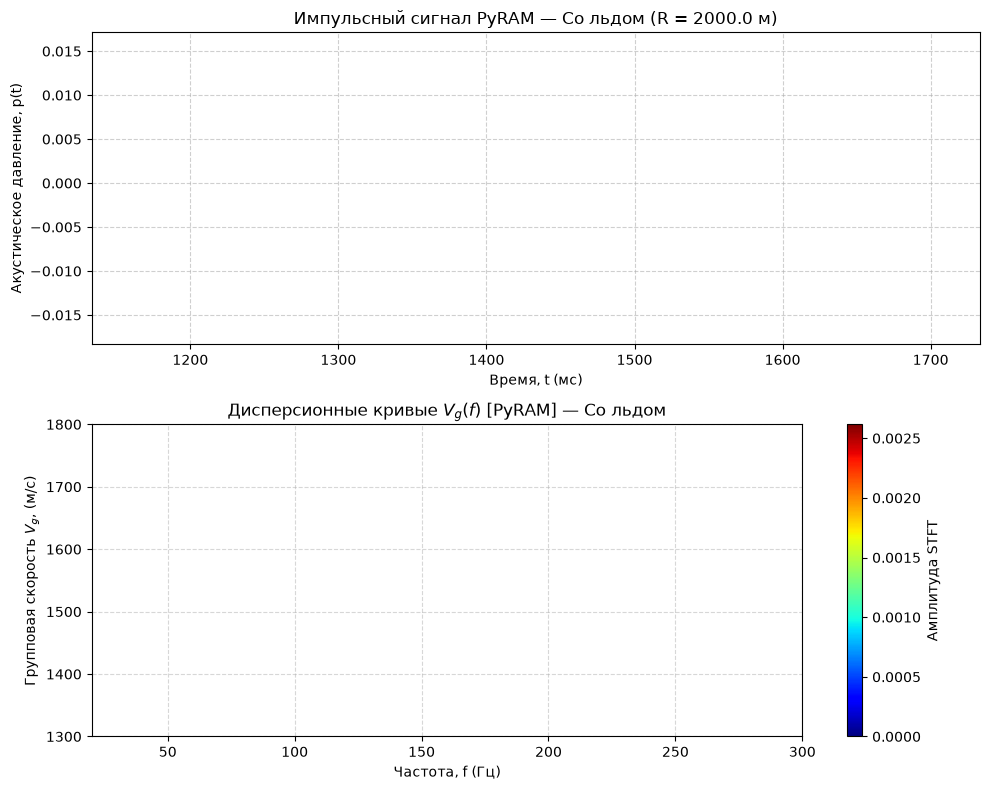

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft
from pyram.PyRAM import PyRAM


def run_pyram_simulation(use_ice=True, r_max=2000.0):
    n_freqs = 128
    freqs = np.linspace(20.0, 300.0, n_freqs)
    P_freq = np.zeros(len(freqs), dtype=complex)

    print(f"--> Запуск расчета PyRAM (USE_ICE = {use_ice}, R = {r_max} м)...")

    for i, f in enumerate(freqs):
        if use_ice:
            # 4-слойная модель со льдом: лед (0-0.4) -> вода (0.4-8.4) -> ил (8.4-9.1)
            z_ss = np.array([0.0, 0.4, 8.4, 9.1])
            cw = np.array([3500.0, 1500.0, 1500.0, 100.0])
            z_sb = np.array([9.1])
            cb = np.array([2100.0])
            rhob = np.array([2.1])
            attn = np.array([800.0])
            z_src = 4.4
            max_depth = 9.1
        else:
            # 3-слойная модель без льда: вода (0-8.0) -> ил (8.0-8.7)
            z_ss = np.array([0.0, 8.0, 8.7])
            cw = np.array([1500.0, 1500.0, 100.0])
            z_sb = np.array([8.7])
            cb = np.array([2100.0])
            rhob = np.array([2.1])
            attn = np.array([800.0])
            z_src = 4.0
            max_depth = 8.7

        rp_ss = np.array([0.0, r_max + 100.0])
        rp_sb = np.array([0.0, r_max + 100.0])

        cw_2d = np.column_stack([cw, cw])
        cb_2d = np.column_stack([cb, cb])
        rhob_2d = np.column_stack([rhob, rhob])
        attn_2d = np.column_stack([attn, attn])

        rbzb = np.array([[0.0, max_depth], [r_max + 100.0, max_depth]])

        model = PyRAM(
            freq=f, zs=z_src, zr=z_src,
            z_ss=z_ss, rp_ss=rp_ss, cw=cw_2d,
            z_sb=z_sb, rp_sb=rp_sb, cb=cb_2d,
            rhob=rhob_2d, attn=attn_2d, rbzb=rbzb,
            rmax=r_max + 100.0
        )
        model.run()

        # Безопасно извлекаем комплексное давление на заданной дальности
        idx_r = np.argmin(np.abs(model.vr - r_max))
        if hasattr(model, 'cpl') and model.cpl is not None:
            P_freq[i] = model.cpl[idx_r]
        elif hasattr(model, 'cpg'):
            idx_z = np.argmin(np.abs(model.vz - z_src))
            P_freq[i] = model.cpg[idx_z, idx_r]

    return freqs, P_freq


if __name__ == "__main__":
    USE_ICE = True  # True — со льдом, False — без льда
    r_observation = 2000.0

    freqs, P_freq = run_pyram_simulation(use_ice=USE_ICE, r_max=r_observation)

    if np.all(P_freq == 0):
        print("Внимание: Массив P_freq заполнен нулями.")
    else:
        print("Расчет успешно завершен, получены ненулевые значения акустического поля!")

    # Синтез временного сигнала и STFT
    df = freqs[1] - freqs[0]
    f0 = 160.0
    spectrum_window = np.exp(-(((freqs - f0) / 80.0) ** 2))

    n_fft = len(freqs) * 2
    p_time = np.fft.irfft(P_freq * spectrum_window, n=n_fft)

    dt = 1.0 / (n_fft * df)
    time_grid = np.arange(len(p_time)) * dt

    fs = 1.0 / dt
    f_stft, t_stft, Zxx = stft(p_time, fs=fs, nperseg=64, noverlap=56, nfft=256)

    t_stft_safe = np.where(t_stft <= 0, 1e-6, t_stft)
    v_group = r_observation / t_stft_safe
    Freq_grid, V_group_grid = np.meshgrid(f_stft, v_group, indexing="ij")

    c0 = 1500.0
    t_arrival_ms = (r_observation / c0) * 1000
    t_min_ms = max(0, t_arrival_ms - 200)
    t_max_ms = t_arrival_ms + 400

    # Визуализация
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
    model_title_suffix = "Со льдом" if USE_ICE else "Без льда"

    ax1.plot(time_grid * 1000, p_time, color="b", lw=1.2)
    ax1.set_title(f"Импульсный сигнал PyRAM — {model_title_suffix} (R = {r_observation} м)")
    ax1.set_xlabel("Время, t (мс)")
    ax1.set_ylabel("Акустическое давление, p(t)")
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.set_xlim([t_min_ms, t_max_ms])

    pcm = ax2.pcolormesh(
        Freq_grid, V_group_grid, np.abs(Zxx),
        shading="gouraud", cmap="jet",
        vmin=0, vmax=np.max(np.abs(Zxx)) * 0.85 if np.max(np.abs(Zxx)) > 0 else 1.0,
    )
    ax2.set_title(f"Дисперсионные кривые $V_g(f)$ [PyRAM] — {model_title_suffix}")
    ax2.set_xlabel("Частота, f (Гц)")
    ax2.set_ylabel("Групповая скорость $V_g$, (м/с)")
    ax2.set_ylim([1300, 1800])
    ax2.set_xlim([20, 300])
    ax2.grid(True, linestyle="--", alpha=0.5)

    fig.colorbar(pcm, ax=ax2, label="Амплитуда STFT")
    plt.tight_layout()
    plt.show()